# Validação dos campos extraídos por regras

O código lê cada anúncio e tenta extrair, por regras, a **recompensa**, a **nação**, a **idade**, o **sexo** e as **marcas no corpo**.
Este caderno mede se essas regras acertam, comparando com uma amostra de anúncios **rotulados à mão** (`tests/fixtures/campos_gold.json`).
Campos `c6`. O caderno **não lê o banco**: só o arquivo de rótulos e o código local.

- **Precisão:** dos anúncios em que o código marcou o campo, quantos estavam certos. Precisão baixa = o código inventa.
- **Cobertura:** dos anúncios que de fato têm o campo, quantos o código achou. Cobertura baixa = o código deixa passar.
- **F1:** uma nota só, que combina as duas.

**Por que por período?** Se a cobertura de um campo cai com o tempo (por exemplo, o OCR dos jornais mais antigos é pior), uma "queda" desse
campo nos anúncios pode ser só **efeito de leitura**, e não uma mudança na sociedade. Medir a cobertura em cada período mostra onde isso pode acontecer.

> **Cuidado ao ler:** os rótulos foram feitos por **Claude**, não pelo grupo de pesquisa; devem ser conferidos por pessoas.
> A amostra é pequena (cerca de 20 fugas por período), então os **intervalos são largos** (intervalo de Wilson de 95%).
> Períodos com menos de 20 anúncios que de fato têm o campo aparecem com círculo aberto nos gráficos.

## Preparação: ler os rótulos e rodar o código local

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from hdb import validacao
from hdb.estatistica import wilson

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
PERIODOS = validacao.PERIODOS
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]
MIN_N = 20
ARQ = RAIZ / "tests" / "fixtures" / "campos_gold.json"
gold = json.loads(ARQ.read_text(encoding="utf-8")) if ARQ.exists() else []
rotulados = [g for g in gold if g.get("rotulos")]
SEM_ROTULOS = not rotulados
if SEM_ROTULOS:
    print("arquivo sem rótulos: rotule tests/fixtures/campos_gold.json")
    R = {c: {} for c in validacao.CAMPOS}
else:
    print(f"{len(rotulados)} anúncios rotulados ({sum(g['tipo'] == 'fuga' for g in rotulados)} fugas, "
          f"{sum(g['tipo'] == 'aluguel' for g in rotulados)} aluguéis)")
    R = validacao.comparar(rotulados)
if len(rotulados) != 120:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 120 anúncios rotulados e agora são {len(rotulados)}: "
          "confira os números dos textos antes de usar.")

CAMPOS = [("recompensa", "Recompensa (fugas)"), ("nacao", "Cita nação (fugas)"), ("marcas", "Marcas no corpo (fugas)"),
          ("idade", "Idade: achou alguma (fugas)"), ("sexo", "Sexo f/m (todos)")]
fmt = lambda t: "–" if t[0] != t[0] else f"{100 * t[0]:.0f}% [{100 * t[1]:.0f}–{100 * t[2]:.0f}]"

120 anúncios rotulados (80 fugas, 40 aluguéis)


## 1. Precisão e cobertura de cada campo
`VP` = o código marcou e estava certo; `FP` = marcou e não devia; `FN` = deixou passar. Entre colchetes, o intervalo de 95%.
Em **idade** a cobertura é "o anúncio traz idade e o código achou alguma"; em **sexo**, "o anúncio diz f ou m e o código disse f ou m"
(um `FP` ali é o código dizer f/m onde o rótulo é "ambos" ou "não diz"). As linhas de **acerto** abaixo olham só os casos em que
rótulo e código acharam algo: a idade tem de cair a ±1 ano da rotulada (ou do intervalo rotulado), e o sexo tem de ser o mesmo.

In [2]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos: rotule `tests/fixtures/campos_gold.json`._"))
else:
    linhas = []
    for campo, nome in CAMPOS:
        c = R[campo].get(validacao.TOTAL)
        if c is None:
            continue
        m = validacao.metricas(c)
        linhas.append({"Campo": nome, "n": m["n"], "VP": c["vp"], "FP": c["fp"], "FN": c["fn"],
                       "Precisão [IC 95%]": fmt(m["precisao"]), "Cobertura [IC 95%]": fmt(m["cobertura"]), "F1 [IC 95%]": fmt(m["f1"])})
    display(pd.DataFrame(linhas).set_index("Campo"))
    acerto = []
    for campo, nome in (("idade_acerto", "Idade a ±1 ano, entre os que ambos acharam"), ("sexo_acerto", "Sexo certo, entre os que ambos acharam")):
        c = R[campo].get(validacao.TOTAL)
        if c:
            acerto.append({"Medida": nome, "n": c["vp"] + c["fp"], "Acertos": c["vp"],
                           "Taxa de acerto [IC 95%]": fmt(wilson(c["vp"], c["vp"] + c["fp"]))})
    display(pd.DataFrame(acerto).set_index("Medida"))

,n,VP,FP,FN,Precisão [IC 95%],Cobertura [IC 95%],F1 [IC 95%]
Campo,,,,,,,
Recompensa (fugas),80,46,0,8,100% [92–100],85% [73–92],92% [85–96]
Cita nação (fugas),80,22,0,1,100% [85–100],96% [79–99],98% [88–100]
Marcas no corpo (fugas),80,24,0,8,100% [86–100],75% [58–87],86% [74–93]
Idade: achou alguma (fugas),80,30,1,2,97% [84–99],94% [80–98],95% [87–98]
Sexo f/m (todos),120,96,9,10,91% [85–95],91% [83–95],91% [86–94]


,n,Acertos,Taxa de acerto [IC 95%]
Medida,,,
"Idade a ±1 ano, entre os que ambos acharam",30,30,100% [89–100]
"Sexo certo, entre os que ambos acharam",96,95,99% [94–100]


**O que mostra (conjunto de desenvolvimento: 120 anúncios rotulados por Claude, 80 fugas e 40 aluguéis).** Atenção: **as regras de recompensa, nação e idade foram corrigidas olhando os erros destes mesmos anúncios**, então estes números são otimistas; a medida que vale é a do conjunto de teste (seção 2c).

- **Recompensa:** precisão 100% (intervalo 92 a 100) e cobertura de **85%** (73 a 92); antes da correção, a cobertura era 57%. Sobram os casos de OCR muito estragado.
- **Marcas no corpo:** precisão 100% e cobertura de 75% (58 a 87); esta regra não foi mexida.
- **Idade:** o código acha 94% das idades que existem (80 a 98; eram 62%), e **quando acha, acerta a idade dentro de ±1 ano em 30 de 30 casos**. Há 1 falso positivo (uma idade lida em "1 aunos", OCR).
- **Nação citada:** precisão 100% (85 a 100) e cobertura de 96% (79 a 99; eram 65%). Palavra com inicial maiúscula depois de "nação" passa a valer como nação citada, e "de Minas" em roupa não conta mais.
- **Sexo (feminino ou masculino):** precisão e cobertura de 91%; entre os casos em que o código e o rótulo acharam algo, o sexo está certo em 95 de 96 (99%). Os erros são anúncios colados ("ambos") e palavras coladas ("humescravo"); esta regra não foi mexida.

## 2. Cobertura por período
Para cada campo, a cobertura (`VP / (VP + FN)`) em cada período, com intervalo de Wilson de 95%. **Círculo aberto** = menos de 20
anúncios que de fato têm o campo naquele período: o número é frágil.

O **teste de queda** compara a cobertura do primeiro período com pelo menos 20 positivos rotulados e a do último
(teste exato de Fisher). Sinalizamos quando a cobertura cai **mais de 15 pontos** e **p < 0,05**; sem isso, não dá para dizer que a leitura piorou.

,antes de 1831,1831–1850,1850–1871,1871–1888
Campo,,,,
Recompensa (fugas),100% [80–100] (n+=15 ⚠),100% [80–100] (n+=15 ⚠),79% [52–92] (n+=14 ⚠),50% [24–76] (n+=10 ⚠)
Cita nação (fugas),91% [62–98] (n+=11 ⚠),100% [72–100] (n+=10 ⚠),100% [34–100] (n+=2 ⚠),– (n+=0 ⚠)
Marcas no corpo (fugas),86% [60–96] (n+=14 ⚠),75% [41–93] (n+=8 ⚠),60% [23–88] (n+=5 ⚠),60% [23–88] (n+=5 ⚠)
Idade: achou alguma (fugas),100% [61–100] (n+=6 ⚠),100% [68–100] (n+=8 ⚠),100% [65–100] (n+=7 ⚠),82% [52–95] (n+=11 ⚠)
Sexo f/m (todos),88% [71–96] (n+=26),96% [82–99] (n+=27),96% [82–99] (n+=27),81% [62–91] (n+=26)


n+ = anúncios que de fato têm o campo; ⚠ = menos de 20.


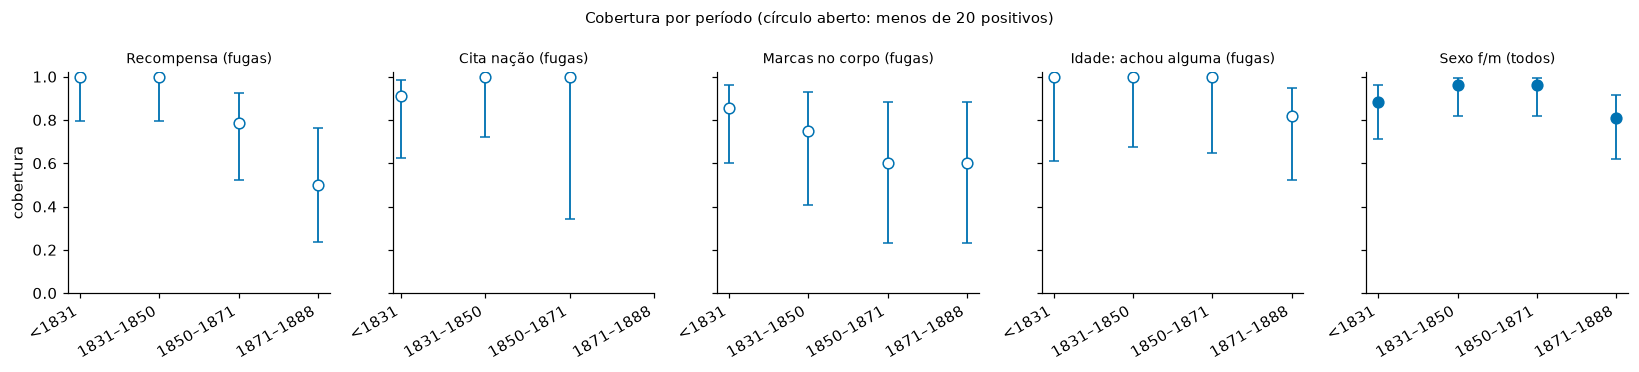

/tmp/ipykernel_1728225/3885827968.py:47: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(linhas).set_index("Campo").fillna(""))


,Resultado,Cobertura do 1º,Cobertura do último,Diferença (pontos),p (Fisher)
Campo,,,,,
Recompensa (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Cita nação (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Marcas no corpo (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Idade: achou alguma (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Sexo f/m (todos),sem queda sinalizada,88%,81%,7.7,0.703


In [3]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos: rotule `tests/fixtures/campos_gold.json`._"))
else:
    linhas = []
    for campo, nome in CAMPOS:
        lin = {"Campo": nome}
        for p in PERIODOS:
            c = R[campo].get(p)
            if c is None:
                lin[p] = "–"
                continue
            pos = c["vp"] + c["fn"]
            lin[p] = f"{fmt(wilson(c['vp'], pos))} (n+={pos}{' ⚠' if pos < MIN_N else ''})"
        linhas.append(lin)
    display(pd.DataFrame(linhas).set_index("Campo"))
    print("n+ = anúncios que de fato têm o campo; ⚠ = menos de 20.")

    fig, eixos = plt.subplots(1, len(CAMPOS), figsize=(3.0 * len(CAMPOS), 3.4), sharey=True)
    for ax, (campo, nome) in zip(eixos, CAMPOS):
        for i, p in enumerate(PERIODOS):
            c = R[campo].get(p)
            pos = (c["vp"] + c["fn"]) if c else 0
            if pos == 0:
                continue
            v, lo, hi = wilson(c["vp"], pos)
            ax.errorbar(i, v, yerr=[[max(v - lo, 0)], [max(hi - v, 0)]], color="#0072B2", capsize=3, lw=1.2)
            ax.plot(i, v, "o", color="#0072B2", mfc="white" if pos < MIN_N else "#0072B2", ms=7, zorder=3)
        ax.set_xticks(range(len(PERIODOS)))
        ax.set_xticklabels([periodo_curto(p).replace("antes de ", "<") for p in PERIODOS], rotation=30, ha="right")
        ax.set_title(nome, fontsize=9)
        ax.set_ylim(0, 1.02)
    eixos[0].set_ylabel("cobertura")
    fig.suptitle("Cobertura por período (círculo aberto: menos de 20 positivos)", fontsize=10)
    fig.tight_layout()
    plt.show()

    linhas = []
    for campo, nome in CAMPOS:
        q = validacao.queda_de_cobertura({p: R[campo][p] for p in PERIODOS if p in R[campo]}, min_n=MIN_N)
        if q == "sem n":
            linhas.append({"Campo": nome, "Resultado": "sem n (menos de 2 períodos com 20 positivos)"})
        else:
            ca, cu, queda, p, sinal = q
            linhas.append({"Campo": nome, "Cobertura do 1º": f"{100 * ca:.0f}%", "Cobertura do último": f"{100 * cu:.0f}%",
                           "Diferença (pontos)": round(queda, 1), "p (Fisher)": round(p, 3),
                           "Resultado": "QUEDA SINALIZADA" if sinal else "sem queda sinalizada"})
    display(pd.DataFrame(linhas).set_index("Campo").fillna(""))

**O que mostra (cobertura por período, no conjunto de desenvolvimento, só entre as fugas que de fato têm o campo):** a **cobertura da recompensa** é 100%, 100%, 79% e **50% em 1871–1888** (10 anúncios): mesmo depois da correção, o código ainda perde mais nos anúncios recentes, que têm o OCR mais sujo; a das marcas vai de 86% a 60%. A cobertura da idade é 100% nos três primeiros períodos e 82% no último (antes da correção era 17% antes de 1831). O teste de queda de cobertura diz **"sem n"** para todos os campos, porque poucos períodos têm 20 anúncios com o campo; cada período tem poucos positivos (⚠).

## 2b. A verdade por período contra o que o código vê
Nas **fugas rotuladas** (20 por período), quantas de fato têm o campo (**verdade**) e quantas o código achou (**código**), e o teste exato de Fisher entre o
primeiro e o último período. Se o código vê uma queda **maior** que a real, parte da queda é **efeito de leitura** (o OCR ou a grafia escondem o campo).
Com 20 anúncios por período o teste tem pouco poder: **p alto não prova que não houve mudança**, só que esta amostra não a mostra.

In [4]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos._"))
else:
    from scipy.stats import fisher_exact
    fugas = [g for g in rotulados if g["tipo"] == "fuga"]
    ext = {g["id"]: validacao.extrair_para_comparar(g["texto"]) for g in fugas}
    def tem(g, campo, fonte):
        if fonte == "verdade":
            r = g["rotulos"]
            return bool(r["nacoes"]) if campo == "nacao" else (r["idade"] is not None if campo == "idade" else bool(r[campo]))
        e = ext[g["id"]]
        return bool(e["nacoes"]) if campo == "nacao" else (e["idade"] is not None if campo == "idade" else bool(e[campo]))
    linhas = []
    for campo, nome in (("recompensa", "Recompensa"), ("nacao", "Nação citada"), ("marcas", "Marcas no corpo"), ("idade", "Idade citada")):
        for fonte in ("verdade", "código"):
            ks = []
            for per in PERIODOS:
                gp = [g for g in fugas if periodo_curto(g["periodo"]) == per]
                ks.append((sum(tem(g, campo, fonte) for g in gp), len(gp)))
            (k1, n1), (k2, n2) = ks[0], ks[-1]
            p = fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])[1]
            linhas.append({"Campo": nome, "Fonte": fonte,
                           **{per: f"{k}/{n} ({100 * k / n:.0f}%)" for per, (k, n) in zip(PERIODOS, ks)},
                           "p (1º × último)": "<0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")})
    display(pd.DataFrame(linhas).set_index(["Campo", "Fonte"]))

antes de 1831    1831–1850    1850–1871    1871–1888 p (1º × último)
Campo           Fonte                                                                       
Recompensa      verdade   15/20 (75%)  15/20 (75%)  14/20 (70%)  10/20 (50%)           0,191
                código    15/20 (75%)  15/20 (75%)  11/20 (55%)   5/20 (25%)           0,004
Nação citada    verdade   11/20 (55%)  10/20 (50%)   2/20 (10%)    0/20 (0%)          <0,001
                código    10/20 (50%)  10/20 (50%)   2/20 (10%)    0/20 (0%)          <0,001
Marcas no corpo verdade   14/20 (70%)   8/20 (40%)   5/20 (25%)   5/20 (25%)           0,010
                código    12/20 (60%)   6/20 (30%)   3/20 (15%)   3/20 (15%)           0,008
Idade citada    verdade    6/20 (30%)   8/20 (40%)   7/20 (35%)  11/20 (55%)           0,200
                código     6/20 (30%)   8/20 (40%)   7/20 (35%)  10/20 (50%)           0,333

**O que mostra (a verdade contra o que o código vê, no conjunto de desenvolvimento):**

- **Recompensa:** o código vê **75%, 75%, 55%, 25%** (p = 0,004) e a **verdade rotulada** é **75%, 75%, 70%, 50%** (p = 0,19). No desenvolvimento, o código ainda **exagera a queda** nos últimos períodos; veja a seção 2c, onde o teste maior mostra que a queda é real.
- **Nação citada:** a verdade é **55%, 50%, 10%, 0%** (p < 0,001) e o código vê **50%, 50%, 10%, 0%**: **a queda é real** e o código a acompanha.
- **Marcas no corpo:** a verdade é **70%, 40%, 25%, 25%** (p = 0,010) e o código vê 60%, 30%, 15%, 15%: **a queda é real**, só um pouco menor no código.
- **Idade citada:** a verdade é **30%, 40%, 35%, 55%** (p = 0,20) e o código vê **30%, 40%, 35%, 50%** (p = 0,33): o código já não esconde as idades dos anúncios antigos.

## 2c. Conjunto de teste: 60 fugas que as regras nunca viram
As regras de recompensa, nação e idade foram corrigidas olhando os erros do conjunto acima (**desenvolvimento**), então os números dele só mostram que
a regra aprendeu o que viu. O **conjunto de teste** (`tests/fixtures/campos_teste.json`, 15 fugas por período, sem repetir nenhuma do desenvolvimento) foi
**rotulado antes de rodar o código novo nele**; é a medida que vale. Abaixo, o código novo no teste e, juntando os dois conjuntos, a **verdade rotulada**
(sem depender do código) por período, com o teste exato de Fisher entre o primeiro e o último.

In [5]:
ARQ_T = RAIZ / "tests" / "fixtures" / "campos_teste.json"
teste = [g for g in json.loads(ARQ_T.read_text(encoding="utf-8")) if g.get("rotulos")] if ARQ_T.exists() else []
if not teste:
    display(Markdown("_Sem conjunto de teste rotulado._"))
else:
    from scipy.stats import fisher_exact
    RT = validacao.comparar(teste)
    linhas = []
    for campo, nome in CAMPOS[:4]:
        m = validacao.metricas(RT[campo][validacao.TOTAL])
        linhas.append({"Campo": nome, "Precisão [IC 95%]": fmt(m["precisao"]), "Cobertura [IC 95%]": fmt(m["cobertura"])})
    print(f"{len(teste)} fugas de teste")
    display(pd.DataFrame(linhas).set_index("Campo"))

    def tem(g, campo):
        r = g["rotulos"]
        return bool(r["nacoes"]) if campo == "nacao" else (r["idade"] is not None if campo == "idade" else bool(r[campo]))
    def vistas(g, campo):
        e = validacao.extrair_para_comparar(g["texto"])
        return bool(e["nacoes"]) if campo == "nacao" else (e["idade"] is not None if campo == "idade" else bool(e[campo]))
    fugas_dev = [g for g in rotulados if g["tipo"] == "fuga"]
    linhas = []
    for campo, nome in (("recompensa", "Recompensa"), ("nacao", "Nação citada"), ("marcas", "Marcas no corpo"), ("idade", "Idade citada")):
        for fonte, conj, fn in (("código, teste", teste, vistas), ("verdade, teste", teste, tem), ("verdade, teste + desenvolvimento", teste + fugas_dev, tem)):
            ks = []
            for per in PERIODOS:
                gp = [g for g in conj if periodo_curto(g["periodo"]) == per]
                ks.append((sum(fn(g, campo) for g in gp), len(gp)))
            (k1, n1), (k2, n2) = ks[0], ks[-1]
            p = fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])[1]
            linhas.append({"Campo": nome, "Fonte": fonte,
                           **{per: f"{k}/{n} ({100 * k / n:.0f}%)" for per, (k, n) in zip(PERIODOS, ks)},
                           "p (1º × último)": "<0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")})
    display(pd.DataFrame(linhas).set_index(["Campo", "Fonte"]))

60 fugas de teste


,Precisão [IC 95%],Cobertura [IC 95%]
Campo,,
Recompensa (fugas),97% [84–99],77% [62–87]
Cita nação (fugas),100% [86–100],100% [86–100]
Marcas no corpo (fugas),100% [77–100],76% [53–90]
Idade: achou alguma (fugas),95% [76–99],86% [67–95]


antes de 1831    1831–1850    1850–1871    1871–1888 p (1º × último)
Campo           Fonte                                                                                                
Recompensa      código, teste                      10/15 (67%)  10/15 (67%)   8/15 (53%)   3/15 (20%)           0,025
                verdade, teste                     13/15 (87%)  13/15 (87%)   9/15 (60%)   4/15 (27%)           0,003
                verdade, teste + desenvolvimento   28/35 (80%)  28/35 (80%)  23/35 (66%)  14/35 (40%)           0,001
Nação citada    código, teste                      11/15 (73%)   8/15 (53%)   5/15 (33%)    0/15 (0%)          <0,001
                verdade, teste                     11/15 (73%)   8/15 (53%)   5/15 (33%)    0/15 (0%)          <0,001
                verdade, teste + desenvolvimento   22/35 (63%)  18/35 (51%)   7/35 (20%)    0/35 (0%)          <0,001
Marcas no corpo código, teste                       8/15 (53%)    1/15 (7%)   3/15 (20%)    1/15 (7%)           0,014
                verdade, teste                      9/15 (60%)   2/15 (13%)   4/15 (27%)   2/15 (13%)           0,021
                verdade, teste + desenvolvimento   23/35 (66%)  10/35 (29%)   9/35 (26%)   7/35 (20%)          <0,001
Idade citada    código, teste                       2/15 (13%)   8/15 (53%)   4/15 (27%)   6/15 (40%)           0,215
                verdade, teste                      2/15 (13%)   9/15 (60%)   4/15 (27%)   7/15 (47%)           0,109
                verdade, teste + desenvolvimento    8/35 (23%)  17/35 (49%)  11/35 (31%)  18/35 (51%)           0,025

**O que mostra (60 fugas de teste, rotuladas por Claude às cegas, antes de rodar o código novo):**

- **Cobertura, antes → depois da correção:** recompensa **72% → 77%** (+5 pontos; a meta era +15, **não foi atingida**), nação **88% → 100%** (+12) e idade **68% → 86%** (+18). Precisão: recompensa 97% → 97%, nação 95% → 100%, idade 100% → 95%; nenhuma caiu mais de 5 pontos. Marcas (76%) e sexo não foram mexidos.
- **Recompensa que ainda escapa (9 de 39):** é OCR muito estragado ("alvi. caras", "ul. vigaras", "gra- Uficado", "graticação", "gratilicará", "alviçãris"). Não ajustei as regras a estas palavras para não ajustar ao próprio teste; fica como **limite**.
- **O que o código vê no teste:** recompensa 67%, 67%, 53%, 20% (p = 0,025) contra a verdade 87%, 87%, 60%, 27% (p = 0,003): o código perde cerca de 20 pontos nos dois primeiros períodos e 7 nos dois últimos, então **já não exagera a queda** (47 pontos contra 60 reais). A meta de ficar a 10 pontos da verdade em cada período **não foi atingida** nos dois primeiros.
- **A verdade, juntando teste e desenvolvimento (35 fugas por período, sem depender do código):** **recompensa 80%, 80%, 66%, 40%** (p = 0,001); **nação 63%, 51%, 20%, 0%** (p < 0,001); **marcas 66%, 29%, 26%, 20%** (p < 0,001); **idade citada 23%, 49%, 31%, 51%** (p = 0,025). A queda da recompensa, antes só "possível" (p = 0,19 com 20 por período), **aparece com o dobro de anúncios rotulados**.
- **Cuidado:** a idade citada **também muda de frequência** (23% a 51%), então a comparação da idade mediana entre períodos junta grupos que citam a idade por motivos diferentes.

## 3. Onde o código erra
Até 10 **falsos negativos** (o campo existe e o código não achou) e 10 **falsos positivos** (o código marcou e não devia) por campo,
com o começo do texto, o rótulo e o que o código extraiu.

In [6]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos: rotule `tests/fixtures/campos_gold.json`._"))
else:
    for campo, nome in CAMPOS:
        c = R[campo].get(validacao.TOTAL)
        if c is None:
            continue
        fn = [e for e in c["erros"] if e["rotulo"] and not e["extraido"]]
        fp = [e for e in c["erros"] if e["extraido"] and not e["rotulo"]]
        outros = [e for e in c["erros"] if e not in fn and e not in fp]   # sexo: rótulo f/m e código disse o contrário etc.
        display(Markdown(f"### {nome}: {c['fn']} falsos negativos, {c['fp']} falsos positivos"))
        for titulo, lista in (("Falsos negativos", fn), ("Falsos positivos", fp), ("Outros erros", outros)):
            if not lista:
                continue
            tabela = pd.DataFrame([{"id": e["id"], "rótulo": e["rotulo"], "código": e["extraido"], "trecho": e["trecho"]}
                                   for e in lista[:10]]).set_index("id")
            display(Markdown(f"**{titulo}** (mostrando {min(10, len(lista))} de {len(lista)})"))
            with pd.option_context("display.max_colwidth", 200):
                display(tabela)

### Recompensa (fugas): 8 falsos negativos, 0 falsos positivos

**Falsos negativos** (mostrando 8 de 8)

,rótulo,código,trecho
id,,,
24019,True,False,"Anda fugido ha mais de um mez o crioulo Napoleão, idade 17 annos, é bastante retinto, tem nariz: chato, e consta que se inculca forro e diz chamar-se Antonio ;"
25871,True,False,"Fogio ha perto ds dous mezes a escrava Anna, € não Morangos “do idada do 40 asno sei oa 003: veta CECrava pertencen 82 copolio do finsdo Erascisco Jowé de Aniar"
27582,True,False,"“FUGIO um preto, ' de nome Henrique, de n e vindo da Eee dolilm. naudes Pinheii a ro, h o, cam! zul, chapéo ta, Foro comprido, baixo, che e dida ele DDOS ; quem"
9085,True,False,"ESCRAVO FUGIDO Dempparecen o dia Setembro do ta Rem, mu 3 corrente enno. da fare-da * nicipro da Lage de Muriahé, provincia do dio de Jenciro, o preto africano"
11880,True,False,". Contintia fugido o escravo de Carreira da Silva & . Januario, pardo, de estatura baixa, sem barba, eita peça, bem reforçado, cem 25 amos presumiveis, Ceará, t"
16392,True,False,"ESCRAVA FUGIDA Fugio no dia 8 do corrente a parda Maria Justina, ja, de 77 cases, magro, baix: omprido Contama alugur-s como < idce-se a quem a levar 4 ma do Co"
21601,True,False,"Fugio, de Manoel de Sá Osorio, o escravo Franklin, cujos signaes são os seguintes: pardo claro, barba cerrada, cabello corrido, baixo, reforçado, pés pequenos,"
21777,True,False,"Continiia fugido o escravo Martiniano, com os seguintes signacs : preto, altura regular, reforçado, falta de dentes na frente e alcijado da mão direita, servind"


### Cita nação (fugas): 1 falsos negativos, 0 falsos positivos

**Falsos negativos** (mostrando 1 de 1)

,rótulo,código,trecho
id,,,
37846,[Cassange],[],"3 Desapareceo huma negra de nome Pamilia, ainda bugal, hindo buscar agoa a Carioca, vestida com vestido de riscado de xadrez rouxo , estatura ordinaria , rosto"


... (7 outputs left out)

,rótulo,código,trecho
id,,,
20746,None,"(1, 1)","Gratifi tin acima a quem appretender o entregar ao administrador do Dr. À. Leitão da Cunha o escravo Hermenegildo, pardo, 1 aunos, labios grossos, cabello encar"


### Sexo f/m (todos): 10 falsos negativos, 9 falsos positivos

**Outros erros** (mostrando 10 de 19)

,rótulo,código,trecho
id,,,
5892,m,nao_diz,"35. Falta, ha 10 dias, humescravo, por nome Paulo, Na» ção Congo, idade 20 e tantos annes; quitandeiro, com os dentes de diante quebrados, e huma cicattiz' junt"
13928,m,nao_diz,"93 José Alves de Castilhos, tem notícia que a bordo de huma embarcação de Guerra, se acha bum cabra official de Tanueiro, justo pa- 2» ? trabalho com o titulo d"
37690,m,nao_diz,"35 Bm 01.0 do mez pp, fugia da Fazenda do Capitão .Justinianao de Oliveira Teguudes, situada em Suruy, hum pirdo escuro de nome Mandel, o qual foi escravo na Fa"
37881,ambos,m,"49 No dia q do corrente mez , (ugio da casa da vinxa de Diogo Gumes Barroso, hum pardo de nome Juão, idade 14 uunos , que paresse caboculo em rasão de ter o cab"
38138,ambos,f,"““PUGIO no dia 13 do corrente, da rua do Aljube , hum esttavo ' por nome Just, de nação Cabiudu; * Votou huintá argola “de ferro ao pescoço + he alto e magro ,"
22661,m,nao_diz,"Avda fugido desde q dia 26 de dezembro de 1830, preto Firmo, criculo , que foi escravo do Dr. Car. rão , da fazenda do Codeço, tento es signaes ses guintos : lu"
24431,nao_diz,m,"EXTMANTO DIARIO DO DIA.6 DE DEZEMBAO Na freguezia do Sacramento ferão presos 'o subdelegado, José Ribeiro da Silva, para ave Miguel Antonio Gonçalves Portella,"
11881,m,ambos,"'ugio da rua de &. Bento m. 430 escravo Jere s, nO dia 28 deDezembro proximo findo: é baixo, . côr um tanto fula e levou calça e camisa de Eme co ao eo dr mr mu"
17767,m,nao_diz,"- O SE Ã é To! 7 re - PEQRAVO FUGIDO qusinheiro, magro e"


## 4. O que isso diz e o que não diz

**O que a validação autoriza:**

1. **A queda da nação citada nas fugas é real** (verdade rotulada, 35 fugas por período: 63% antes de 1831, nenhuma em 1871–1888) e **a queda das marcas no corpo também** (66% para 20%).
2. **A queda da recompensa é real**, mas o código a mede com viés: a verdade rotulada vai de **80% para 40%** (p = 0,001) e o código novo vê 67% para 20% no teste. A direção e o tamanho da queda (em pontos) concordam; **o nível do código é menor que o real** (ele perde recompensas escritas com OCR estragado), então o número do código (66% para 26%) vale como tendência, não como proporção exata.
3. **Idade:** o código agora acha 86% das idades (teste), mas a fração de fugas que citam idade também sobe de 23% para 51%; a **alta da idade mediana continua frágil** (poucos anúncios nos extremos).
4. **Sexo** é o campo mais confiável (99% de acerto quando o código acha); ressalva só para anúncios colados.

**Limites:** 35 fugas por período (15 do teste e 20 do desenvolvimento) dão intervalos largos; **os rótulos são de Claude, não do grupo** (os arquivos `tests/fixtures/campos_gold.json` e `campos_teste.json` permitem ao grupo conferir); a recompensa não atingiu a meta de cobertura; o conjunto de teste foi usado **uma vez**, e uma nova rodada de ajuste exigiria sortear outro.

**O que fazer depois:** marcas no corpo (76%) e sexo em anúncios colados são os campos que ainda perdem; para a recompensa, o que falta é OCR estragado, que regras novas só resolveriam palavra a palavra.